# ราคารถมือสอง — Multiple Linear Regression (MLR) (เวอร์ชัน 4, โมเดลพื้นฐาน)
- ข้อมูล: `merged_min50.csv` (รถทุกรุ่นมีอย่างน้อย 50 คัน) การตรวจข้อมูล การแบ่ง train/val/test (80 / 10 / 10 แบบ stratified ตามรุ่น) และ one-hot **เหมือนกันทุกตัวอักษร** กับ notebook MLR4 / DT4 / RF4 / XGB4
- ตัวแปรที่ใช้ **ไม่ได้กำหนดเอง** แต่เลือกจาก train ในหัวข้อ 5 (กรองตัวซ้ำซ้อน + วิธีเลือกของโมเดลนี้) และใช้ cross-validation 5 fold
- **ทำนายราคาตรง ๆ** (ไม่แปลง log) และวัดผลบนราคาจริง
- โมเดลพื้นฐาน = **OLS ธรรมดา** ไม่ใส่ตัวช่วยใด ๆ (ไม่แปลง target, ไม่ถ่วงน้ำหนัก, ไม่ตัด outlier) แล้ว **ทดสอบ assumption ทั้ง 5 กลุ่ม** ตามจริง ผ่านหรือไม่ผ่านรายงานตามนั้น
- notebook นี้รันจากบนลงล่างได้เอง ใช้แค่ไฟล์ CSV

> ต้อง mount Google Drive ก่อนรัน

## 0. Import และค่าตั้งต้น
รวมค่าที่ใช้ทั้ง notebook ไว้ที่เดียว จะได้แก้ง่าย (สัดส่วน train/val/test ก็อยู่ตรงนี้)

In [1]:
import os
import time
import hashlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import lilliefors

DATA_PATH = "/content/drive/MyDrive/Project/cardb/merged_min50.csv"
# ใช้รันในเครื่อง: ถ้าไม่เจอ path ของ Drive ให้ใช้ไฟล์ในเครื่องแทน (บน Colab ไม่มีผล)
if not os.path.exists(DATA_PATH):
    DATA_PATH = r"D:\Claude\project_car_used\data\newdata\cleaned\merged_min50.csv"

SEED = 99            # เลขสุ่มคงที่ รันกี่ครั้งก็ได้ผลเหมือนเดิม
CURRENT_YEAR = 2026  # ปีที่เก็บข้อมูล ใช้คำนวณอายุรถ
TRAIN_SIZE = 0.8
VAL_SIZE = 0.1
TEST_SIZE = 0.1

EXPECTED_SHA256 = "1a817cf9acc35c2ee244117c17a6ae93bbe5c33ccbe54fd63c47dc0f22ce88b9"   # ลายนิ้วมือของไฟล์ข้อมูล (ตัด \r ออกก่อนคำนวณ)
REDUNDANT_MAX = 0.95   # คู่ตัวแปรที่สัมพันธ์กันตั้งแต่ค่านี้ขึ้นไป ถือว่าซ้ำซ้อน
TOL = 0.02             # ตัดตัวแปรได้ ถ้า CV MAE แย่ลงไม่เกิน 2%
N_FOLDS = 5            # จำนวน fold ของ cross-validation

NUM_COLS = ["engine_capacity", "mileage", "car_age"]                              # ตัวแปรตัวเลข
CAT_COLS = ["brand", "model", "car_type", "fuel_type", "gear_type", "color"]      # ตัวแปรกลุ่ม

pd.set_option("display.width", 200, "display.max_columns", 50)
# คำเตือนภายในของ scikit-learn/joblib ตอนเรียก RandomForest แบบหลาย core (ไม่เกี่ยวกับข้อมูลหรือผลลัพธ์) ซ่อนไว้ไม่ให้ท่วมผลลัพธ์
warnings.filterwarnings("ignore", message=".*sklearn.utils.parallel.delayed.*")

## 1. โหลดข้อมูล

In [2]:
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

## 2. ตรวจคุณภาพข้อมูล (data check) — ทุกโมเดลตรวจชุดเดียวกัน
ข้อมูลชุดนี้ทำความสะอาดมาแล้ว ขั้นนี้ **แค่ตรวจและรายงาน** ไม่ได้เรียนรู้อะไรจากข้อมูล ไม่แก้ข้อมูล
- ตรวจ **sha256** ของไฟล์ (ลายนิ้วมือของไฟล์) ว่าเป็นไฟล์เวอร์ชันเดียวกับที่ใช้ทำผลทั้งหมด ถ้าไม่ตรงโค้ดจะหยุดทันที (ตัดตัวอักษร `\r` ออกก่อน เพื่อให้ได้ค่าเดียวกันทั้งบน Windows และ Colab)
- ตรวจขนาดตาราง ชนิดข้อมูล (dtypes) ค่าว่าง แถวซ้ำ ค่าต่ำสุด/สูงสุดของตัวเลข
- ตรวจกฎพื้นฐาน: ราคา ไมล์ เครื่องยนต์ต้องมากกว่า 0 และปีรถต้องไม่เกินปีที่เก็บข้อมูล
- ดูจำนวนค่า (levels) ของตัวแปรกลุ่มแต่ละตัว และจำนวนรถต่อรุ่น
- รายงานเพิ่ม (ไม่แก้): สัดส่วนไมล์ = 2,500 กม. (ค่ากลางของช่วง "ต่ำกว่า 5,000" ที่บางแหล่งใช้แทนไมล์ที่ไม่ทราบ) และ กม./ปี สูงสุด

In [3]:
with open(DATA_PATH, "rb") as f:
    file_hash = hashlib.sha256(f.read().replace(b"\r", b"")).hexdigest()
assert file_hash == EXPECTED_SHA256, f"ไฟล์ข้อมูลไม่ตรงกับเวอร์ชันที่ใช้ทำผล (sha256 ที่ได้ = {file_hash})"
print("sha256 ตรงกับไฟล์ที่คาดไว้:", file_hash[:16], "...")

print("\nshape:", df.shape)
print("\ndtypes:"); print(df.dtypes.to_string())
print("\nค่าว่างต่อคอลัมน์:"); print(df.isna().sum().to_string())
print("\nแถวซ้ำทั้งแถว:", int(df.duplicated().sum()))
print("\nค่าต่ำสุด / สูงสุดของตัวเลข:")
print(df.select_dtypes("number").agg(["min", "max"]).T.to_string())

assert df.notna().all().all(), "มีค่าว่าง"
assert (df["price"] > 0).all(), "มีราคาที่ไม่เป็นบวก"
assert (df["mileage"] > 0).all(), "มีไมล์ที่ไม่เป็นบวก"
assert (df["engine"] > 0).all(), "มีเครื่องยนต์ที่ไม่เป็นบวก"
assert (df["year"] <= CURRENT_YEAR).all(), "มีปีรถที่เกินปีที่เก็บข้อมูล"
print("\nผ่าน: ไม่มีค่าว่าง, price / mileage / engine > 0, year <= ปีที่เก็บข้อมูล ทุกแถว")

print("\nจำนวน levels ของตัวแปรกลุ่ม:")
print(df[["brand", "model", "car_type", "fuel", "gear", "color"]].nunique().to_string())
per_model = df.groupby(["brand", "model"]).size()
print(f"\nรถต่อรุ่น: น้อยสุด {per_model.min()} | มัธยฐาน {per_model.median():.0f} | มากสุด {per_model.max()} ({len(per_model)} รุ่น)")

# รายงานเพิ่ม (ไม่แก้ข้อมูล)
km_per_year = df["mileage"] / (CURRENT_YEAR - df["year"]).clip(lower=1)
print(f"\nไมล์ = 2,500 กม.: {(df['mileage'] == 2500).sum():,} แถว ({(df['mileage'] == 2500).mean():.1%})")
print(f"กม./ปี สูงสุด: {km_per_year.max():,.0f}")

sha256 ตรงกับไฟล์ที่คาดไว้: 1a817cf9acc35c2e ...

shape: (50540, 10)

dtypes:
brand         str
model         str
year        int64
price       int64
mileage     int64
engine      int64
gear          str
fuel          str
color         str
car_type      str

ค่าว่างต่อคอลัมน์:
brand       0
model       0
year        0
price       0
mileage     0
engine      0
gear        0
fuel        0
color       0
car_type    0

แถวซ้ำทั้งแถว: 0

ค่าต่ำสุด / สูงสุดของตัวเลข:
           min      max
year      2006     2026
price    27900  2000000
mileage    102   300000
engine    1000     3600

ผ่าน: ไม่มีค่าว่าง, price / mileage / engine > 0, year <= ปีที่เก็บข้อมูล ทุกแถว

จำนวน levels ของตัวแปรกลุ่ม:
brand        20
model       118
car_type      7
fuel          3
gear          2
color        20

รถต่อรุ่น: น้อยสุด 50 | มัธยฐาน 200 | มากสุด 2988 (118 รุ่น)

ไมล์ = 2,500 กม.: 2,640 แถว (5.2%)
กม./ปี สูงสุด: 60,000


## 3. เตรียมแถวข้อมูล
- เปลี่ยนชื่อคอลัมน์ให้ตรงกับชื่อที่ใช้ทุก notebook (`engine` -> `engine_capacity`, `fuel` -> `fuel_type`, `gear` -> `gear_type`)
- สร้าง `car_age = ปีที่เก็บข้อมูล - year` แล้วตัดคอลัมน์ `year` ทิ้ง เพราะข้อมูลซ้ำกันเป๊ะ ๆ (`year = 2026 - car_age`)
- ไม่ตัดแถวเพิ่ม ใช้ตามไฟล์ `merged_min50.csv` (ทำความสะอาดและกรองรุ่นที่มีรถน้อยกว่า 50 คันมาแล้ว)

In [4]:
df = df.rename(columns={"engine": "engine_capacity", "fuel": "fuel_type", "gear": "gear_type"})
df["car_age"] = CURRENT_YEAR - df["year"]
df = df.drop(columns="year")
assert df[NUM_COLS + CAT_COLS + ["price"]].notna().all().all()
print(df.shape)
df.head()

(50540, 10)


,brand,model,price,mileage,engine_capacity,gear_type,fuel_type,color,car_type,car_age
0,HONDA,CR-V,1129000,42500,2000,Automatic,Hybrid,Grey,SUV,2
1,TOYOTA,VELLFIRE,999000,147500,2500,Automatic,Hybrid,White,MPV,11
2,BMW,530E,899000,107500,2000,Automatic,Hybrid,White,Sedan,5
3,HONDA,HR-V,759000,97500,1500,Automatic,Hybrid,Grey,SUV,3
4,TOYOTA,YARIS CROSS,749000,32500,1500,Automatic,Hybrid,Grey,SUV,2


## 4. แบ่ง train / val / test (80 / 10 / 10)
- `train` ใช้สอนโมเดล (และเลือกตัวแปร), `val` ใช้ตรวจโมเดลระหว่างทำ, `test` ใช้วัดผลสุดท้ายครั้งเดียว
- แบ่งแบบ **stratified ตาม (ยี่ห้อ, รุ่น)**: รถแต่ละรุ่นถูกแบ่งเข้าทั้ง 3 ชุดตามสัดส่วน 80 / 10 / 10 ของรุ่นนั้นเอง ทุกรุ่นจึงอยู่ครบทั้ง train, val และ test (รุ่นที่น้อยสุดมี 50 คัน ได้ราว 40 / 5 / 5 คัน)
- แบ่ง 2 ขั้น: (1) แยก train 80% ออก (2) แบ่ง 20% ที่เหลือครึ่งต่อครึ่งเป็น val กับ test ทั้งสองขั้นใช้ `stratify` และ `random_state = SEED`
- **ทุกโมเดล (MLR / DT / RF / XGB) ใช้โค้ดแบ่งชุดนี้เหมือนกันทุกตัวอักษร** จะได้ชุดข้อมูลเดียวกัน เทียบกันได้ตรง ๆ (เซลล์ถัดไปพิมพ์ลายนิ้วมือของ index ไว้เทียบข้าม notebook)

In [5]:
# ขั้น 1: แยก train 80% (stratified ตาม ยี่ห้อ + รุ่น)
model_key = df["brand"] + "|" + df["model"]
train, temp = train_test_split(df, train_size=TRAIN_SIZE, stratify=model_key, random_state=SEED)

# ขั้น 2: แบ่งส่วนที่เหลือครึ่งต่อครึ่ง เป็น val กับ test (stratified เหมือนเดิม)
val, test = train_test_split(temp, test_size=TEST_SIZE / (VAL_SIZE + TEST_SIZE),
                             stratify=model_key.loc[temp.index], random_state=SEED)

print("train / val / test:", len(train), len(val), len(test))

train / val / test: 40432 5054 5054


In [6]:
# ตรวจว่าทุกรุ่นอยู่ครบทั้ง 3 ชุด และสัดส่วนใกล้ 80 / 10 / 10
counts = pd.concat({"train": model_key.loc[train.index].value_counts(),
                    "val": model_key.loc[val.index].value_counts(),
                    "test": model_key.loc[test.index].value_counts()}, axis=1).fillna(0).astype(int)
counts["total"] = counts.sum(axis=1)
assert (counts[["train", "val", "test"]] > 0).all().all(), "มีรุ่นที่หายไปจากบางชุด"
print(f"ทุกรุ่น ({len(counts)} รุ่น) อยู่ครบทั้ง train, val และ test")

share = counts[["train", "val", "test"]].div(counts["total"], axis=0)
print("\nสัดส่วนของแต่ละรุ่นในแต่ละชุด (ควรใกล้ 0.8 / 0.1 / 0.1):")
print(share.agg(["min", "max"]).round(3).to_string())
print("\nรุ่นที่สัดส่วนต่างจากเป้ามากที่สุด 5 รุ่น:")
off = (share - pd.Series({"train": TRAIN_SIZE, "val": VAL_SIZE, "test": TEST_SIZE})).abs().max(axis=1).sort_values(ascending=False)
print(pd.concat([counts.loc[off.index[:5]], off.head(5).rename("max |ต่างจากเป้า|").round(3)], axis=1).to_string())

# ลายนิ้วมือของการแบ่ง: ทุก notebook ต้องได้ค่าเดียวกัน
fingerprint = hashlib.md5(",".join(f"{name}:{','.join(map(str, sorted(part.index)))}"
                                   for name, part in (("train", train), ("val", val), ("test", test))).encode()).hexdigest()
print("\nลายนิ้วมือของการแบ่ง (md5 ของ index):", fingerprint)

ทุกรุ่น (118 รุ่น) อยู่ครบทั้ง train, val และ test



สัดส่วนของแต่ละรุ่นในแต่ละชุด (ควรใกล้ 0.8 / 0.1 / 0.1):
     train    val   test
min  0.792  0.089  0.093
max  0.806  0.107  0.113

รุ่นที่สัดส่วนต่างจากเป้ามากที่สุด 5 รุ่น:
                    train  val  test  total  max |ต่างจากเป้า|
MG|VS HEV              42    5     6     53              0.013
VOLVO|XC90             50    6     7     63              0.011
MERCEDES-BENZ|S300     43    5     6     54              0.011
NISSAN|SYLPHY          45    5     6     56              0.011
TOYOTA|PRIUS           45    5     6     56              0.011

ลายนิ้วมือของการแบ่ง (md5 ของ index): ab8dee837041fc111cf8b997eec7d2b1


## 5. เลือกตัวแปร (variable selection) — ใช้เฉพาะ train
ไม่ได้ใส่ตัวแปรทุกตัวเข้าโมเดลตรง ๆ แต่ให้ข้อมูลช่วยเลือก ทำ 2 ชั้น โดยใช้ **train เท่านั้น** (val/test ไม่ถูกแตะ):

| ชั้น | ทำอะไร |
|---|---|
| 1. กรองตัวแปรซ้ำซ้อน (redundancy filter) | ดูทุกคู่ตัวแปร ถ้าสัมพันธ์กันเกิน 0.95 ถือว่าซ้ำกัน ตัดออกหนึ่งตัวในคู่ |
| 2. เลือกตามวิธีของโมเดลนั้น | MLR: GVIF + ตัดแบบถอยหลัง (backward elimination) ด้วย F-test และ CV MAE / ต้นไม้: permutation importance + ตัดแบบถอยหลัง |

### 5.1 ชั้น 1: กรองความซ้ำซ้อน
วัดความสัมพันธ์ของแต่ละคู่ให้อยู่ในช่วง 0-1 เหมือนกันหมด จะได้ใช้เกณฑ์เดียว (`REDUNDANT_MAX` = 0.95):
- **ตัวเลข x ตัวเลข:** |Pearson r|
- **กลุ่ม x กลุ่ม:** Cramér's V (แบบปรับ bias ของ Bergsma 2013) V ไม่บอกทิศทาง จึงใช้ **Theil's U** ช่วย: U(a|b) = สัดส่วนความไม่แน่นอนของ a ที่ b อธิบายได้ ถ้า U(a|b) ≈ 1 แปลว่า b มีข้อมูลของ a อยู่แล้ว ตัด a (ตัวที่หยาบกว่า)
- **ตัวเลข x กลุ่ม:** correlation ratio η (รากของสัดส่วนความแปรปรวนของตัวเลขที่กลุ่มอธิบายได้)

**ใครโดนตัดอะไร:** คู่ที่เกือบซ้ำ (>= 0.95 แต่ไม่ถึง 1) เป็นปัญหาของ **MLR เท่านั้น** เพราะตัวแปรที่สัมพันธ์กันทำให้ค่าสัมประสิทธิ์ไม่นิ่ง (เช่น `brand` ถูก `model` กำหนดได้ทั้งหมด dummy ของ brand จึงเป็นผลบวกของ dummy ของ model พอดี ทำให้ OLS คำนวณไม่ได้) ต้นไม้ไม่เดือดร้อน และตัวแปรที่หยาบกว่า (เช่น `brand`) ยังช่วยต้นไม้ได้ ต้นไม้จึงตัดเฉพาะตัวที่ซ้ำกัน **เป๊ะ** (|r| = 1) แล้วให้ชั้น 2 ตัดสินส่วนที่เหลือ

In [7]:
def entropy(x):
    p = x.value_counts(normalize=True)
    return -(p * np.log(p)).sum()


def theil_u(a, b):
    """U(a|b): สัดส่วน entropy ของ a ที่ b อธิบายได้ (1 = b กำหนด a ได้หมด)"""
    return 1 - sum(len(g) / len(a) * entropy(g) for _, g in a.groupby(b)) / entropy(a)


def cramers_v(a, b):
    """Cramér's V แบบปรับ bias (Bergsma 2013)"""
    t = pd.crosstab(a, b)
    n = t.values.sum()
    r, k = t.shape
    phi2 = max(0, stats.chi2_contingency(t, correction=False)[0] / n - (k - 1) * (r - 1) / (n - 1))
    r_corr, k_corr = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(k_corr - 1, r_corr - 1))


def eta(x, group):
    """correlation ratio: ตัวเลข x ถูกอธิบายด้วยกลุ่ม group ได้เท่าไร"""
    m = x.mean()
    return np.sqrt(sum(len(s) * (s.mean() - m) ** 2 for _, s in x.groupby(group)) / ((x - m) ** 2).sum())


rows = []
for i, a in enumerate(NUM_COLS):
    for b in NUM_COLS[i + 1:]:
        rows.append(dict(a=a, b=b, measure="|r|", value=abs(train[a].corr(train[b]))))
for i, a in enumerate(CAT_COLS):
    for b in CAT_COLS[i + 1:]:
        rows.append(dict(a=a, b=b, measure="Cramér's V", value=cramers_v(train[a], train[b]),
                         U_a_given_b=theil_u(train[a], train[b]), U_b_given_a=theil_u(train[b], train[a])))
for a in NUM_COLS:
    for b in CAT_COLS:
        rows.append(dict(a=a, b=b, measure="η", value=eta(train[a], train[b])))
pairs = pd.DataFrame(rows).sort_values("value", ascending=False)
pairs["redundant"] = pairs["value"] >= REDUNDANT_MAX
pairs.round(3).head(15)

,a,b,measure,value,U_a_given_b,U_b_given_a,redundant
3,brand,model,Cramér's V,0.999,1.000,0.536,True
8,model,car_type,Cramér's V,0.979,0.413,0.967,True
19,engine_capacity,model,η,0.921,NaN,NaN,False
9,model,fuel_type,Cramér's V,0.848,0.181,0.783,False
10,model,gear_type,Cramér's V,0.737,0.053,0.597,False
20,engine_capacity,car_type,η,0.726,NaN,NaN,False
13,car_type,gear_type,Cramér's V,0.690,0.111,0.531,False
21,engine_capacity,fuel_type,η,0.673,NaN,NaN,False
12,car_type,fuel_type,Cramér's V,0.638,0.267,0.494,False
5,brand,fuel_type,Cramér's V,0.524,0.140,0.326,False


**การตัดสินใจ:** ในแต่ละคู่ที่ซ้ำซ้อน ตัดตัวที่อีกตัวมีข้อมูลของมันอยู่แล้ว
- คู่ตัวเลข: ตัดตัวหลัง (`b`)
- คู่กลุ่ม: ตัด `a` ถ้า U(a|b) > U(b|a) ไม่งั้นตัด `b` (ตัดตัวที่หยาบกว่า)
- คู่ η ที่เกินเกณฑ์: ให้คนตัดสินเอง (โค้ดจะหยุดเตือน)

In [8]:
dropped = {}
for _, p in pairs[pairs.redundant].iterrows():
    if p.measure == "|r|":
        victim = p.b
    elif p.measure == "Cramér's V":
        victim = p.a if p.U_a_given_b > p.U_b_given_a else p.b
    else:
        raise ValueError(f"คู่ η เกินเกณฑ์ ต้องตัดสินใจเอง: {p.a} x {p.b}")
    dropped.setdefault(victim, f"{p.a} x {p.b}: {p.measure} = {p.value:.3f}")

ALL_VARS = NUM_COLS + CAT_COLS
LAYER1_MLR = [c for c in ALL_VARS if c not in dropped]        # MLR: ตัดทุกคู่ที่ซ้ำซ้อน
exact_dup = pairs[(pairs.measure == "|r|") & (pairs.value > 1 - 1e-9)]
LAYER1_TREE = [c for c in ALL_VARS if c not in set(exact_dup["b"])]   # ต้นไม้: ตัดเฉพาะตัวที่ซ้ำกันเป๊ะ

print("ตัวแปรที่ถูกตัดในชั้น 1 (MLR):")
print(pd.Series(dropped, name="ตัดเพราะ").to_string() if dropped else "  (ไม่มี)")
print("\nMLR   -> ไปชั้น 2:", LAYER1_MLR)
print("ต้นไม้ -> ไปชั้น 2:", LAYER1_TREE)

ตัวแปรที่ถูกตัดในชั้น 1 (MLR):
brand          brand x model: Cramér's V = 0.999
car_type    model x car_type: Cramér's V = 0.979

MLR   -> ไปชั้น 2: ['engine_capacity', 'mileage', 'car_age', 'model', 'fuel_type', 'gear_type', 'color']
ต้นไม้ -> ไปชั้น 2: ['engine_capacity', 'mileage', 'car_age', 'brand', 'model', 'car_type', 'fuel_type', 'gear_type', 'color']


### 5.2 เตรียมก่อนเลือกชั้น 2: one-hot และ cross-validation
ชั้น 2 วัดผลด้วย **cross-validation** บน train เท่านั้น: `KFold(5, shuffle=True, random_state=99)` แบ่ง train เป็น 5 ส่วน สลับกันเป็นส่วนสอบ
- target คือ **ราคาจริง (บาท)** ทุกโมเดล (ไม่แปลง log) และ CV MAE วัดเป็นบาท
- `TOL` = 2%: การตัดตัวแปรหนึ่งตัวยอมให้ CV MAE แย่ลงได้ไม่เกิน 2% **เทียบกับตอนใช้ตัวแปรครบ** (ไม่ใช่เทียบรอบก่อน) ดังนั้นตัดไปหลายรอบรวมแล้วก็แย่ลงไม่เกิน 2%

**one-hot (dummy) เหมือนกันทั้ง 4 โมเดล** ฟังก์ชัน `make_design` แปลงตัวแปรกลุ่มเป็นคอลัมน์ 0/1 ต่อ 1 ระดับ:
- ตัดระดับอ้างอิงออก 1 ระดับต่อตัวแปร (ระดับที่พบบ่อยสุดใน train) เพราะถ้าเก็บครบ คอลัมน์ dummy ของตัวแปรเดียวกันรวมกันได้ 1 พอดี ทำให้ OLS คำนวณไม่ได้ ใช้วิธีเดียวกันทุกโมเดลเพื่อให้ตารางตัวแปร X เหมือนกันทุกตัวอักษร
- ระดับ (levels) เรียนรู้จากชุดที่ fit เท่านั้น (ใน CV คือ fold train) ค่าที่ไม่เคยเห็นจะได้ 0 ทุกคอลัมน์
- ชื่อคอลัมน์ `ตัวแปร=ระดับ` เช่น `model=VIOS` เพื่อรู้ว่า dummy แต่ละคอลัมน์เป็นของตัวแปรไหน (`owner`) การเลือกตัวแปรทำทีละ **ตัวแปรเดิม** (เช่น `model` ทั้งก้อน) ไม่ใช่ทีละคอลัมน์ dummy

In [9]:
def owner(col):
    """ชื่อตัวแปรเจ้าของคอลัมน์ เช่น 'brand=HONDA' -> 'brand', 'mileage' -> 'mileage'"""
    return col.split("=")[0]


def make_design(d, fit_d, variables):
    """ตารางตัวแปร X: ตัวเลขใช้ค่าเดิม ตัวแปรกลุ่มทำ one-hot (ตัดระดับอ้างอิง = ระดับที่พบบ่อยสุดใน fit_d)"""
    X = d[[v for v in variables if v in NUM_COLS]].astype(float)
    for v in [v for v in variables if v in CAT_COLS]:
        counts = fit_d[v].value_counts()
        levels = sorted(counts.index, key=lambda l: (-counts[l], l))[1:]    # [1:] = ตัดระดับอ้างอิงออก
        dummies = (d[v].to_numpy(dtype=object)[:, None] == np.array(levels, dtype=object)).astype(float)
        X = X.join(pd.DataFrame(dummies, index=d.index, columns=[f"{v}={l}" for l in levels]))
    return X


folds = list(KFold(N_FOLDS, shuffle=True, random_state=SEED).split(train))
y_train = train["price"].values   # target = ราคาจริง (บาท)

### ค่าตั้งต้นเพิ่มของ MLR (ใช้ในการเลือกตัวแปรและทดสอบ assumption)

In [10]:
ALPHA = 0.05          # ระดับนัยสำคัญที่ใช้ทั้ง F-test และทดสอบ assumption
DW_RANGE = (1.5, 2.5) # Durbin-Watson ที่ถือว่าผ่าน (residual ไม่สัมพันธ์กัน)
VIF_MAX = 7           # VIF / GVIF^(1/df) ที่ยอมรับได้
SW_MAX_N = 5000       # Shapiro-Wilk ใช้ได้ถึง n = 5,000 จึงสุ่ม residual มาทดสอบ
RESET_POWER = 3       # Ramsey RESET: เติม ŷ², ŷ³

### 5.3 ชั้น 2 สำหรับ MLR: GVIF แล้ว backward elimination (F-test + CV MAE)
1. **GVIF** (generalized VIF): VIF ใช้กับตัวแปรกลุ่มที่มีหลาย dummy ไม่ได้ตรง ๆ จึงใช้ GVIF ต่อ 1 ตัวแปร = det(R ของมัน) x det(R ของที่เหลือ) / det(R ทั้งหมด) (R = correlation matrix ของตารางตัวแปร X) แล้วเทียบ GVIF^(1/df) กับ `VIF_MAX` = 7 (ปรับให้อยู่ในหน่วยเดียวกับ VIF ปกติ) ตัวไหนเกินจะถูกตัดก่อน
2. **backward elimination:** แต่ละรอบทำ joint F-test ของแต่ละตัวแปร (H0: สัมประสิทธิ์ทุกตัวของมัน = 0) และวัด CV MAE ตอนไม่มีมัน ตัวที่ **p > `ALPHA` และ CV MAE แย่ลงไม่เกิน `TOL`** ตัดได้ ตัดตัวที่ p สูงสุดทีละตัว วนจนไม่มีตัวที่ตัดได้

In [11]:
def gvif(X, variables):
    """GVIF ต่อตัวแปร = det(R_ตัวมัน) * det(R_ที่เหลือ) / det(R_ทั้งหมด) (R = correlation matrix)"""
    X = X.loc[:, X.std() > 0]
    R = np.corrcoef(X.values, rowvar=False)
    logdet = lambda M: np.linalg.slogdet(M)[1]
    owners = np.array([owner(c) for c in X.columns])
    out = {}
    for v in variables:
        mask = owners == v
        out[v] = dict(df=int(mask.sum()), GVIF=np.exp(logdet(R[np.ix_(mask, mask)]) + logdet(R[np.ix_(~mask, ~mask)]) - logdet(R)))
    table = pd.DataFrame(out).T
    table["GVIF^(1/df)"] = table["GVIF"] ** (1 / table["df"])
    return table


vif_tab = gvif(make_design(train, train, LAYER1_MLR), LAYER1_MLR)
vif_tab["pass"] = vif_tab["GVIF^(1/df)"] < VIF_MAX
display(vif_tab.round(2))
MLR_VARS = [v for v in LAYER1_MLR if vif_tab.loc[v, "pass"]]
print("หลังตรวจ GVIF:", MLR_VARS)

,df,GVIF,GVIF^(1/df),pass
engine_capacity,1.0,7.04,7.04,False
mileage,1.0,1.43,1.43,True
car_age,1.0,1.88,1.88,True
model,117.0,424.89,1.05,True
fuel_type,2.0,24.66,4.97,True
gear_type,1.0,2.23,2.23,True
color,19.0,2.16,1.04,True


หลังตรวจ GVIF: ['mileage', 'car_age', 'model', 'fuel_type', 'gear_type', 'color']


In [12]:
def mlr_cv(variables):
    """CV MAE (ราคาจริง) ของ OLS"""
    errors = []
    for tr, va in folds:
        fold_train, fold_val = train.iloc[tr], train.iloc[va]
        Xa = sm.add_constant(make_design(fold_train, fold_train, variables), has_constant="add")
        Xb = sm.add_constant(make_design(fold_val, fold_train, variables), has_constant="add")
        beta = np.linalg.lstsq(Xa.values, y_train[tr], rcond=None)[0]
        errors.append(np.abs(Xb.values @ beta - y_train[va]).mean())
    return np.mean(errors)


def f_tests(variables):
    """joint F-test ของแต่ละตัวแปร (H0: สัมประสิทธิ์ทุกตัวของมัน = 0)"""
    X = sm.add_constant(make_design(train, train, variables))
    res = sm.OLS(y_train, X).fit()
    out = {}
    for v in variables:
        idx = [i for i, c in enumerate(X.columns) if c != "const" and owner(c) == v]
        R = np.zeros((len(idx), X.shape[1]))
        R[range(len(idx)), idx] = 1
        f = res.f_test(R)
        out[v] = dict(df=len(idx), F=float(np.squeeze(f.fvalue)), p=float(f.pvalue))
    return pd.DataFrame(out).T


start = time.time()
current = MLR_VARS.copy()
base_mae = mlr_cv(current)
selection_log = []
while len(current) > 1:
    ft = f_tests(current)
    ft["cv_MAE_without"] = [mlr_cv([x for x in current if x != v]) for v in ft.index]
    ft["loss_vs_all"] = ft["cv_MAE_without"] / base_mae - 1
    ft["droppable"] = (ft["p"] > ALPHA) & (ft["loss_vs_all"] <= TOL)
    selection_log.append(ft.assign(round=len(selection_log) + 1))
    if not ft["droppable"].any():
        break
    victim = ft.loc[ft.droppable, "p"].idxmax()
    current.remove(victim)
    print(f"รอบ {len(selection_log)}: ตัด {victim}")

MLR_SELECTED = current
FEATURES = MLR_SELECTED
print(f"ใช้เวลา {time.time() - start:.0f} วินาที | CV MAE ตอนมีครบ {base_mae:,.0f}")
print("ตัวแปรที่เลือก:", MLR_SELECTED)
print("ตัวแปรที่ถูกตัด:", [v for v in ALL_VARS if v not in MLR_SELECTED])
pd.concat(selection_log).reset_index(names="variable").set_index(["round", "variable"]).round(4)

ใช้เวลา 12 วินาที | CV MAE ตอนมีครบ 93,123
ตัวแปรที่เลือก: ['mileage', 'car_age', 'model', 'fuel_type', 'gear_type', 'color']
ตัวแปรที่ถูกตัด: ['engine_capacity', 'brand', 'car_type']


df           F    p  cv_MAE_without  loss_vs_all  droppable
round variable                                                                 
1     mileage      1.0   1214.7532  0.0      94712.4107       0.0171      False
      car_age      1.0  29300.2111  0.0     121517.3418       0.3049      False
      model      117.0    831.5742  0.0     170113.1880       0.8268      False
      fuel_type    2.0    335.5557  0.0      94037.5171       0.0098      False
      gear_type    1.0   1076.8275  0.0      94979.6769       0.0199      False
      color       19.0     15.5822  0.0      93495.5850       0.0040      False

## 6. เตรียมตัวแปร (features) และ target
ใช้เฉพาะตัวแปรที่เลือกในหัวข้อ 5 (`FEATURES`)

- **target คือ `price` (ราคาจริง ไม่แปลง log)** ทุกโมเดลทำนายราคาเป็นบาทตรง ๆ และวัดผลบนราคาจริงเลย ไม่มีขั้นแปลงกลับ
- ตัวแปรตัวเลข (`engine_capacity`, `mileage`, `car_age`) ใช้ค่าดิบ ไม่แปลง ไม่ปรับสเกล
- ตัวแปรกลุ่มทำ one-hot ด้วย `make_design` ตัวเดียวกับที่ใช้เลือกตัวแปร (ระดับอ้างอิงและ levels มาจาก train เท่านั้น)
- ตรวจว่า train / val / test มีคอลัมน์ชุดเดียวกัน ลำดับเดียวกัน และไม่มีค่าว่าง

In [13]:
X_train = make_design(train, train, FEATURES)
X_val = make_design(val, train, FEATURES)
X_test = make_design(test, train, FEATURES)
y_val, y_test = val["price"].values, test["price"].values

assert list(X_train.columns) == list(X_val.columns) == list(X_test.columns)
assert not (X_train.isna().any().any() or X_val.isna().any().any() or X_test.isna().any().any())
print("ตัวแปรที่ใช้:", FEATURES)
print("X train / val / test:", X_train.shape, X_val.shape, X_test.shape)
print("\ntarget (ราคา, บาท) ของ train:"); print(train["price"].describe().round(0).to_string())

ตัวแปรที่ใช้: ['mileage', 'car_age', 'model', 'fuel_type', 'gear_type', 'color']
X train / val / test: (40432, 141) (5054, 141) (5054, 141)

target (ราคา, บาท) ของ train:
count      40432.0
mean      553186.0
std       326645.0
min        49000.0
25%       339000.0
50%       467000.0
75%       689000.0
max      2000000.0


## 7. ฟังก์ชันวัดผล
ใช้ 4 ตัวชี้วัด (คำนวณบนราคาจริงเป็นบาท):
- **RMSE** = รากของค่าเฉลี่ย error ยกกำลังสอง ลงโทษ error ใหญ่ ๆ หนัก (หน่วยบาท ยิ่งน้อยยิ่งดี)
- **MAE** = ค่าเฉลี่ยของ error แบบไม่สนทิศทาง อ่านง่าย "พลาดเฉลี่ยกี่บาท" (ยิ่งน้อยยิ่งดี)
- **MAPE** = error เฉลี่ยเป็นสัดส่วนของราคาจริง เช่น 0.11 = พลาดเฉลี่ย 11% (ยิ่งน้อยยิ่งดี)
- **R²** = โมเดลอธิบายความผันผวนของราคาได้กี่ส่วน (1 = สมบูรณ์แบบ, 0 = ไม่ดีกว่าทายค่าเฉลี่ย)

In [14]:
def score(actual, predicted):
    """วัดผลบนราคาจริง (บาท)"""
    return {
        "RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "MAE": mean_absolute_error(actual, predicted),
        "MAPE": np.mean(np.abs(predicted / actual - 1)),
        "R2": r2_score(actual, predicted),
    }

## 8. โมเดลพื้นฐาน: OLS ธรรมดา และ cross-validation
โมเดลพื้นฐานคือ **OLS ธรรมดา** บนราคาจริง (ไม่แปลง target, ไม่ถ่วงน้ำหนัก, ไม่ตัด outlier, ไม่เติมตัวช่วยใด ๆ) โดยตั้งใจ เพราะรอบนี้อยากเห็นว่าโมเดลเส้นตรงพื้นฐาน **ผ่านหรือไม่ผ่าน assumption** ตามจริง ก่อนจะเพิ่มตัวช่วยในเวอร์ชันถัดไป (ต่างจาก MLR3 ที่ใส่ Box-Cox, FGLS, ตัด outlier เพื่อให้ผ่าน)
- ใช้ตัวแปรที่เลือกในหัวข้อ 5 (`FEATURES`) และตาราง X จาก `make_design`
- ราคาที่ทำนายได้ **ติดลบได้** เพราะโมเดลเส้นตรงบนราคาไม่มีขอบล่าง จะนับจำนวนไว้ ไม่ปรับแก้
- cross-validation: เทรนบน 4 ใน 5 ส่วนของ train วัดผลบนส่วนที่เหลือ ทำสลับกัน 5 รอบ (fold เดียวกับที่ใช้เลือกตัวแปร)

In [15]:
cv_rows = []
for tr, va in folds:
    fold_train, fold_val = train.iloc[tr], train.iloc[va]
    Xa = sm.add_constant(make_design(fold_train, fold_train, FEATURES), has_constant="add")
    Xb = sm.add_constant(make_design(fold_val, fold_train, FEATURES), has_constant="add")
    beta = np.linalg.lstsq(Xa.values, y_train[tr], rcond=None)[0]
    cv_rows.append(score(y_train[va], Xb.values @ beta))
cv = pd.DataFrame(cv_rows, index=[f"fold {i}" for i in range(1, N_FOLDS + 1)])
display(cv.round(4))
cv_summary = pd.DataFrame({"mean": cv.mean(), "SD": cv.std()})
cv_summary.round(4)

,RMSE,MAE,MAPE,R2
fold 1,135275.4764,92005.2390,0.2038,0.8239
fold 2,137351.1525,93247.5718,0.2053,0.8214
fold 3,135848.5673,92821.3769,0.2048,0.8259
fold 4,138473.1699,93582.2913,0.2046,0.8237
fold 5,138754.4336,93957.2764,0.2080,0.8234


,mean,SD
RMSE,137140.5599,1546.9784
MAE,93122.7511,752.1386
MAPE,0.2053,0.0016
R2,0.8237,0.0016


In [16]:
# เทรนบน train ทั้งชุด (OLS ธรรมดา)
X_tr_c = sm.add_constant(X_train, has_constant="add")
final = sm.OLS(y_train, X_tr_c).fit()
print(f"จำนวนคอลัมน์ X = {X_tr_c.shape[1]} (รวม const) | rank = {np.linalg.matrix_rank(X_tr_c.values)} | R² (train) = {final.rsquared:.4f}")
assert np.linalg.matrix_rank(X_tr_c.values) == X_tr_c.shape[1], "ตาราง X ไม่เต็ม rank"

จำนวนคอลัมน์ X = 142 (รวม const) | rank = 142 | R² (train) = 0.8251


## 9. ทดสอบ assumption (5 กลุ่ม)
| Assumption | Test | กฎผ่าน |
|---|---|---|
| Independence | Durbin-Watson (residual เรียงตามลำดับแถวในไฟล์) | DW อยู่ใน `DW_RANGE` (1.5-2.5) |
| Homoscedasticity | Breusch-Pagan (บนทุกคอลัมน์ของ X), White (แบบพิเศษ: ŷ, ŷ²) | p > ALPHA |
| Normality | Kolmogorov-Smirnov, Lilliefors (residual ทั้งหมด), Shapiro-Wilk (สุ่ม 5,000 ตัว) | p > ALPHA |
| Multicollinearity | VIF ของทุกคอลัมน์ใน X (สรุปรายตัวแปร) | < `VIF_MAX` (7) |
| **Linearity** | **Ramsey RESET** (เติม ŷ², ŷ³ แล้ว F-test ว่าดีขึ้นไหม) | p > ALPHA |

**ผลคือผลตามจริงของโมเดลพื้นฐาน** ไม่ได้ปรับโมเดลเพื่อให้ test ผ่าน test ที่ไม่ผ่านบอกว่าเวอร์ชันถัดไปควรแก้ตรงไหน

**residual ที่ใช้ทดสอบ:** เป็น residual ของ **train** ชนิด internally studentized r = e / (σ̂ · √(1 − h)) โดย h คือ leverage การหารด้วย √(1 − h) ทำให้ทุกแถวมีความแปรปรวนเท่ากัน แถวที่ h >= 0.99 ถูกตัดออกจากการทดสอบเพราะ residual เป็น 0 โดยโครงสร้าง ส่วน VIF คำนวณจาก X ของ train ทั้งหมด

**Shapiro-Wilk กับขนาดตัวอย่าง:** p-value ของ scipy ใช้ได้ถึง n = 5,000 จึงสุ่ม residual 5,000 ตัว (seed 99) มาทดสอบ

**Ramsey RESET:** ถ้าความสัมพันธ์เป็นเส้นตรงจริง การเติม ŷ² และ ŷ³ เข้าไปในโมเดลไม่ควรช่วยอธิบายอะไรเพิ่ม (H0: สัมประสิทธิ์ของมัน = 0) ใช้ F-test กำหนด power = 3 ไว้ล่วงหน้า (ไม่ได้ปรับเพื่อให้ผ่าน) คำนวณเองโดยใช้ ŷ ที่มาตรฐานแล้วก่อนยกกำลัง (ได้ F เท่า `statsmodels.linear_reset` ในทางทฤษฎี แต่ไม่เกิดปัญหาตัวเลข `SingularMatrixWarning` จากสเกลของ ŷ³)

In [17]:
def row(group, test, statistic, p, rule, ok):
    return dict(assumption=group, test=test, statistic=statistic, p_value=p, rule=rule, passed=bool(ok))


# residual แบบ studentized: r = e / (σ̂ * sqrt(1 - h))
h = final.get_influence().hat_matrix_diag
r_all = pd.Series(final.resid.values / (np.sqrt(final.scale) * np.sqrt(np.clip(1 - h, 1e-12, None))), index=train.index)
ok_rows = h < 0.99
r = r_all[ok_rows]
X_ok = X_tr_c[ok_rows]
fitted_ok = final.fittedvalues.values[ok_rows]
print(f"ใช้ residual {len(r):,} จาก {len(r_all):,} แถว (ตัดแถวที่ leverage >= 0.99 ออก {int((~ok_rows).sum())} แถว)")


def residual_tests(r, X, fitted):
    """r: studentized residual (Series, index = แถวเดิมในไฟล์), X: ตาราง X ที่ใช้ fit, fitted: ค่าที่ fit ได้"""
    out = []
    dw = durbin_watson(r.sort_index().values)
    out.append(row("Independence", "Durbin-Watson", dw, np.nan, f"{DW_RANGE[0]}-{DW_RANGE[1]}", DW_RANGE[0] <= dw <= DW_RANGE[1]))

    def r2_of(y, Z):
        b = np.linalg.lstsq(Z, y, rcond=None)[0]
        u = y - Z @ b
        return 1 - u @ u / ((y - y.mean()) @ (y - y.mean()))

    lm = len(r) * r2_of(r.values ** 2, X.values)
    p = stats.chi2.sf(lm, np.linalg.matrix_rank(X.values) - 1)   # = het_breuschpagan (Koenker)
    out.append(row("Homoscedasticity", "Breusch-Pagan", lm, p, "p > α", p > ALPHA))
    lm = len(r) * r2_of(r.values ** 2, sm.add_constant(np.column_stack([fitted, fitted ** 2])))
    p = stats.chi2.sf(lm, 2)
    out.append(row("Homoscedasticity", "White (special form: ŷ, ŷ²)", lm, p, "p > α", p > ALPHA))
    d, p = stats.kstest((r - r.mean()) / r.std(ddof=0), "norm")
    out.append(row("Normality", "Kolmogorov-Smirnov", d, p, "p > α", p > ALPHA))
    s = r.sample(min(len(r), SW_MAX_N), random_state=SEED)
    w, p = stats.shapiro(s.values)
    out.append(row("Normality", f"Shapiro-Wilk (random {len(s):,} residuals)", w, p, "p > α", p > ALPHA))
    d, p = lilliefors(r.values, dist="norm")
    out.append(row("Normality", "Lilliefors", d, p, "p > α", p > ALPHA))
    return out


def vif_rows(X):
    Z = X.drop(columns="const")
    v = pd.Series(np.diag(np.linalg.pinv(np.corrcoef(Z.values, rowvar=False), hermitian=True)), index=Z.columns)   # = VIF
    groups = {f"{c} (max of dummies)" if c in CAT_COLS else c: [k for k in v.index if owner(k) == c] for c in FEATURES}
    return [row("Multicollinearity", f"VIF {name}", v[cols].max(), np.nan, f"< {VIF_MAX:g} (max at {v[cols].idxmax()})", v[cols].max() < VIF_MAX)
            for name, cols in groups.items() if cols]


def reset_row(res, X):
    """Ramsey RESET: เติม ŷ², ŷ³ แล้ว F-test ว่าลด RSS ได้จริงไหม
    ใช้ ŷ ที่มาตรฐานแล้ว (z) แทน ŷ ดิบ: ช่วงเวกเตอร์เดียวกัน ได้ F เท่าเดิม แต่ไม่เจอปัญหาตัวเลขเพราะสเกลต่างกันมาก"""
    z = (res.fittedvalues - res.fittedvalues.mean()) / res.fittedvalues.std()
    extra = np.column_stack([z.values ** k for k in range(2, RESET_POWER + 1)])
    Z = np.column_stack([X.values, extra])
    y = res.model.endog
    rss0 = res.ssr
    rss1 = ((y - Z @ np.linalg.lstsq(Z, y, rcond=None)[0]) ** 2).sum()
    q, df2 = extra.shape[1], len(y) - Z.shape[1]
    f = ((rss0 - rss1) / q) / (rss1 / df2)
    p = stats.f.sf(f, q, df2)
    return row("Linearity", f"Ramsey RESET (power {RESET_POWER}, F-test)", f, p, "p > α", p > ALPHA)


results = pd.DataFrame(residual_tests(r, X_ok, fitted_ok) + vif_rows(X_tr_c) + [reset_row(final, X_tr_c)])
results["result"] = np.where(results["passed"], "PASS", "FAIL")
display(results.drop(columns="passed").round(4))

group_summary = results.groupby("assumption", sort=False)["passed"].agg(["sum", "size", "all"])
group_summary.columns = ["tests passed", "tests total", "group passes"]
display(group_summary)
MLR_PASSES_ALL = bool(results["passed"].all())
print(f"ผ่านทั้งหมด: {int(results['passed'].sum())} / {len(results)} tests | ครบทั้ง 5 กลุ่ม = {MLR_PASSES_ALL}")

ใช้ residual 40,431 จาก 40,432 แถว (ตัดแถวที่ leverage >= 0.99 ออก 1 แถว)


,assumption,test,statistic,p_value,rule,result
0,Independence,Durbin-Watson,1.8020,NaN,1.5-2.5,PASS
1,Homoscedasticity,Breusch-Pagan,10390.4863,0.000,p > α,FAIL
2,Homoscedasticity,"White (special form: ŷ, ŷ²)",6306.7948,0.000,p > α,FAIL
3,Normality,Kolmogorov-Smirnov,0.0923,0.000,p > α,FAIL
4,Normality,"Shapiro-Wilk (random 5,000 residuals)",0.9044,0.000,p > α,FAIL
5,Normality,Lilliefors,0.0923,0.001,p > α,FAIL
6,Multicollinearity,VIF mileage,1.4288,NaN,< 7 (max at mileage),PASS
7,Multicollinearity,VIF car_age,1.7911,NaN,< 7 (max at car_age),PASS
8,Multicollinearity,VIF model (max of dummies),3.4903,NaN,< 7 (max at model=CITY),PASS
9,Multicollinearity,VIF fuel_type (max of dummies),11.0932,NaN,< 7 (max at fuel_type=Diesel),FAIL


,tests passed,tests total,group passes
assumption,,,
Independence,1,1,True
Homoscedasticity,0,2,False
Normality,0,3,False
Multicollinearity,5,6,False
Linearity,0,1,False


ผ่านทั้งหมด: 6 / 13 tests | ครบทั้ง 5 กลุ่ม = False


## 10. กราฟ residual ของโมเดล
- กราฟซ้าย: residual เทียบกับ ŷ ถ้า residual กระจายเท่ากันตลอด (homoscedastic) ควรเป็นแถบแนวนอนสม่ำเสมอ (รูปกรวยคือความแปรปรวนไม่คงที่)
- กลาง: Q-Q plot ยิ่งใกล้เส้นทแยง residual ยิ่งใกล้ normal
- ขวา: histogram ของ residual เทียบกับ N(0,1)
- แถวล่าง: residual เทียบกับตัวแปรตัวเลขที่เลือก เส้นแดง LOWESS คือค่าเฉลี่ยเลื่อนของ residual ถ้าความสัมพันธ์เป็นเส้นตรงพอดี เส้นควรแบนอยู่ที่ 0

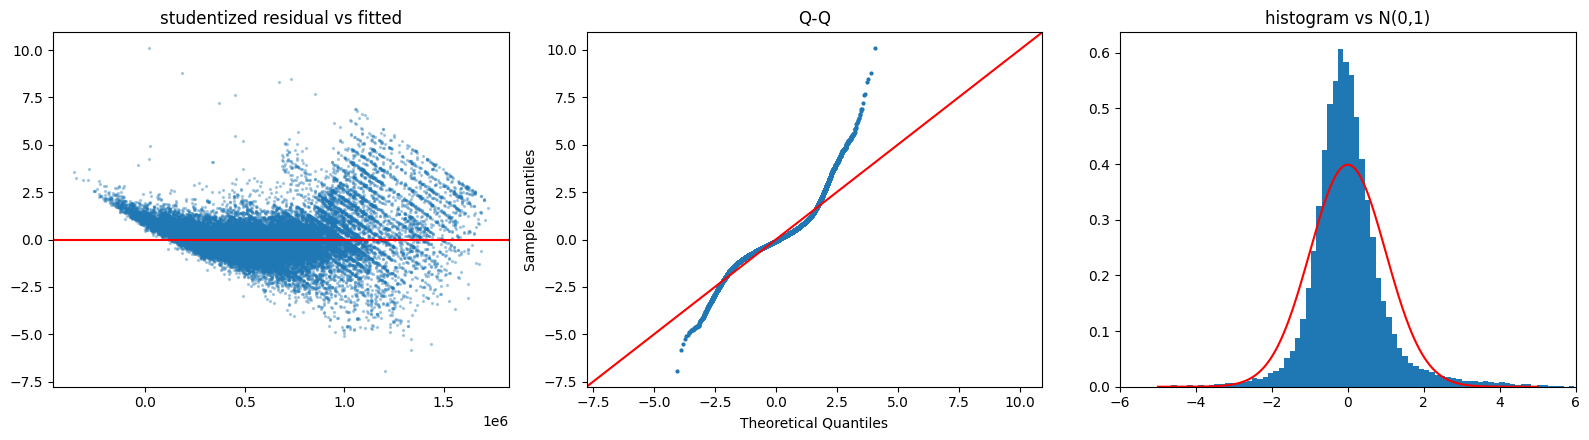

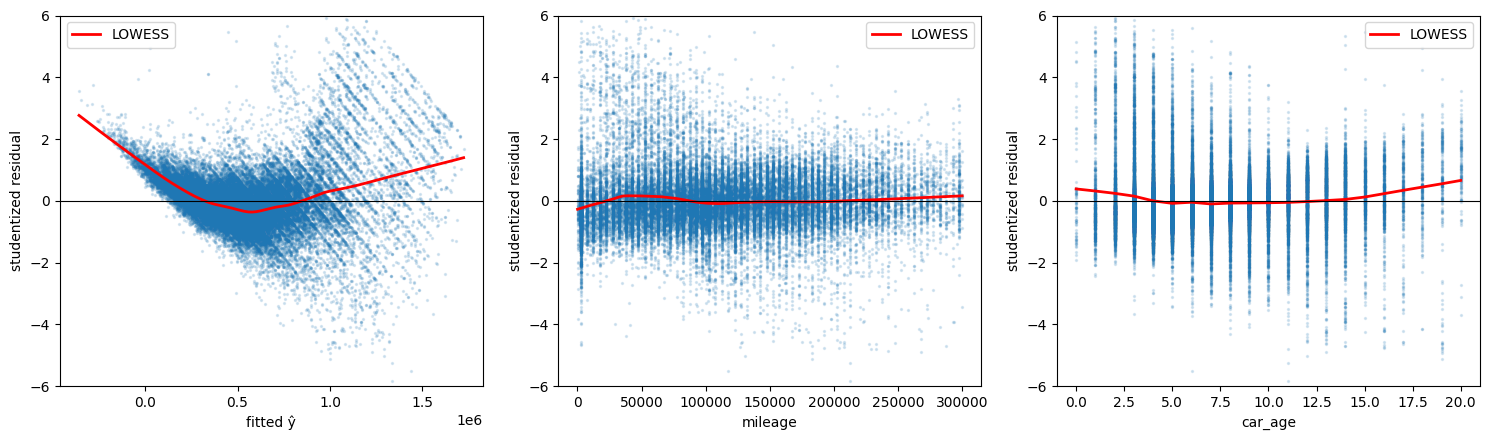

fitted ŷ             LOWESS ต่ำสุด -0.364  สูงสุด +2.766
mileage              LOWESS ต่ำสุด -0.272  สูงสุด +0.165
car_age              LOWESS ต่ำสุด -0.100  สูงสุด +0.661


In [18]:
from statsmodels.nonparametric.smoothers_lowess import lowess

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].scatter(fitted_ok, r, s=2, alpha=.3)
ax[0].axhline(0, c="r")
ax[0].set_title("studentized residual vs fitted")
sm.qqplot(r, line="45", fit=True, ax=ax[1], markersize=2)
ax[1].set_title("Q-Q")
ax[2].hist((r - r.mean()) / r.std(), bins=120, density=True)
xs = np.linspace(-5, 5, 300)
ax[2].plot(xs, stats.norm.pdf(xs), c="r")
ax[2].set_xlim(-6, 6)
ax[2].set_title("histogram vs N(0,1)")
plt.tight_layout()
plt.show()

panels = [("fitted ŷ", fitted_ok)] + [(c, train.loc[r.index, c].values) for c in NUM_COLS if c in FEATURES]
fig, ax = plt.subplots(1, len(panels), figsize=(5 * len(panels), 4.5))
ax = np.atleast_1d(ax)
for a, (name, x) in zip(ax, panels):
    a.scatter(x, r.values, s=2, alpha=.15)
    smooth = lowess(r.values, x, frac=0.3, it=0, delta=0.01 * (x.max() - x.min()))   # เส้น LOWESS = ค่าเฉลี่ยเลื่อนของ residual
    a.plot(smooth[:, 0], smooth[:, 1], c="red", lw=2, label="LOWESS")
    a.axhline(0, c="k", lw=.8)
    a.set_ylim(-6, 6)
    a.set_xlabel(name)
    a.set_ylabel("studentized residual")
    a.legend()
plt.tight_layout()
plt.show()

# ขนาดความโค้ง: ช่วงต่ำสุด-สูงสุดของเส้น LOWESS (หน่วยเดียวกับ residual ที่ SD ≈ 1)
for name, x in panels:
    smooth = lowess(r.values, x, frac=0.3, it=0, delta=0.01 * (x.max() - x.min()))
    print(f"{name:20s} LOWESS ต่ำสุด {smooth[:, 1].min():+.3f}  สูงสุด {smooth[:, 1].max():+.3f}")

## 11. วัดผลบน validation และ test (test ครั้งเดียว)
- ทำนายราคาตรง ๆ จาก `X @ β` (ไม่มี back-transform) ราคาที่ทำนายได้ติดลบนับไว้ แต่ไม่ปรับแก้
- ตารางสรุปเทียบผลบน train, CV, val และ test

In [19]:
beta = final.params.values
train_pred = X_tr_c.values @ beta
val_pred = sm.add_constant(X_val, has_constant="add").values @ beta
this_train = {"model": "MLR", "set": "train", **score(y_train, train_pred)}
this_val = {"model": "MLR", "set": "val", **score(y_val, val_pred)}

# วัดผลบน test ครั้งเดียว (ไม่ใช้ test เลือกอะไรเลย)
test_pred = sm.add_constant(X_test, has_constant="add").values @ beta
this_test = {"model": "MLR", "set": "test", **score(y_test, test_pred)}
print("ราคาที่ทำนายได้ติดลบ (train / val / test):", int((train_pred < 0).sum()), int((val_pred < 0).sum()), int((test_pred < 0).sum()))
summary = pd.DataFrame([{"model": "MLR", "set": "train (fit ทั้งชุด)", **{k: v for k, v in this_train.items() if k in ("RMSE", "MAE", "MAPE", "R2")}},
                        {"model": "MLR", "set": "CV 5 fold (mean)", **cv_summary["mean"].to_dict()},
                        {"model": "MLR", "set": "val", **{k: v for k, v in this_val.items() if k in ("RMSE", "MAE", "MAPE", "R2")}},
                        {"model": "MLR", "set": "test", **{k: v for k, v in this_test.items() if k in ("RMSE", "MAE", "MAPE", "R2")}}]).set_index(["model", "set"])
summary.round(4)

ราคาที่ทำนายได้ติดลบ (train / val / test): 542 65 70


RMSE         MAE    MAPE      R2
model set                                                         
MLR   train (fit ทั้งชุด)  136593.9334  92752.3623  0.2045  0.8251
      CV 5 fold (mean)     137140.5599  93122.7511  0.2053  0.8237
      val                  136522.4417  91901.4457  0.2010  0.8288
      test                 134570.5124  92308.9216  0.2069  0.8226

## 12. ราคาจริง vs ราคาที่ทำนาย (test)
จุดยิ่งใกล้เส้นประสีแดง ยิ่งทายแม่น (แกนเป็นสเกล log เพื่อให้เห็นทั้งรถถูกและรถแพง) ราคาที่ทำนายได้ติดลบหรือเป็นศูนย์ (เกิดได้กับ MLR) วาดบนแกน log ไม่ได้ จึงไม่ถูกวาด และบอกจำนวนไว้ในชื่อกราฟ

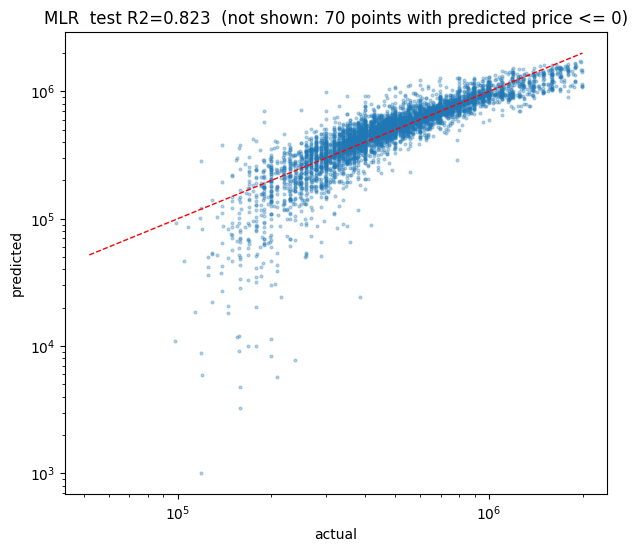

In [20]:
fig, ax = plt.subplots(figsize=(7, 6))
shown = test_pred > 0   # แกน log วาดค่าที่ <= 0 ไม่ได้
ax.scatter(y_test[shown], test_pred[shown], s=4, alpha=0.3)
price_range = [y_test.min(), y_test.max()]
ax.plot(price_range, price_range, "r--", lw=1)   # เส้นที่ทายถูกพอดี
ax.set(xscale="log", yscale="log", xlabel="actual", ylabel="predicted",
       title=f"MLR  test R2={r2_score(y_test, test_pred):.3f}  (not shown: {(~shown).sum()} points with predicted price <= 0)")
plt.show()

## 13. ตัวแปรแต่ละตัวสำคัญไหม (joint F-test บนโมเดลสุดท้าย)
F-test ของ "สัมประสิทธิ์ทุกตัวของตัวแปรนี้ = 0" บนโมเดลที่ fit ด้วย train ทั้งชุด ยิ่ง F มาก ตัวแปรนั้นยิ่งอธิบายราคาได้มาก

In [21]:
imp = f_tests(FEATURES)
imp["share of F"] = imp["F"] / imp["F"].sum()
imp.sort_values("F", ascending=False).round(4)

,df,F,p,share of F
car_age,1.0,29300.2111,0.0,0.8940
mileage,1.0,1214.7532,0.0,0.0371
gear_type,1.0,1076.8275,0.0,0.0329
model,117.0,831.5742,0.0,0.0254
fuel_type,2.0,335.5557,0.0,0.0102
color,19.0,15.5822,0.0,0.0005


## 14. ทายพลาดตรงไหน (validation)
แยกตามอายุรถ และ 15 รุ่นที่พลาดมากที่สุด (เฉพาะรุ่นที่มีอย่างน้อย 10 คันใน val)

In [22]:
errors = val.copy()
errors["pred"] = val_pred
errors["abs_err"] = (errors["pred"] - errors["price"]).abs()   # พลาดกี่บาท
errors["ape"] = errors["abs_err"] / errors["price"]            # พลาดกี่ % ของราคา
errors["age_bin"] = pd.cut(errors["car_age"], [-1, 2, 5, 8, 12, 16, 20, 25])

by_age = errors.groupby("age_bin", observed=True).agg(
    n=("ape", "size"), MAE=("abs_err", "mean"), MAPE=("ape", "mean"))
display(by_age.round(3))

by_model = errors.groupby(["brand", "model"]).agg(
    n=("ape", "size"), MAE=("abs_err", "mean"), MAPE=("ape", "mean"), med_price=("price", "median"))
by_model = by_model[by_model["n"] >= 10]
by_model.sort_values("MAE", ascending=False).head(15).round(3)

,n,MAE,MAPE
age_bin,,,
"(-1, 2]",262,146443.007,0.161
"(2, 5]",1603,95276.931,0.149
"(5, 8]",1666,75023.890,0.138
"(8, 12]",989,84255.956,0.219
"(12, 16]",441,111182.615,0.466
"(16, 20]",93,172284.332,0.886


n         MAE   MAPE  med_price
brand         model                                     
MERCEDES-BENZ C350      16  371475.740  0.419   568500.0
              C220      27  301236.439  0.224  1390000.0
TOYOTA        ALPHARD   55  292137.600  0.312  1599000.0
              VELLFIRE  39  271699.923  0.260  1379000.0
BMW           320D      35  262982.912  0.303   890000.0
              330E      24  257521.804  0.343  1039000.0
MERCEDES-BENZ E300      21  248904.018  0.345  1150000.0
              GLC220    10  226636.974  0.136  1645000.0
              GLA200    30  225866.978  0.323   899000.0
MINI          COOPER    11  220595.021  0.401   465000.0
BMW           X3        24  215461.858  0.282  1032500.0
              530E      25  196392.307  0.224   899000.0
              X1        62  169429.246  0.286   678500.0
              520D      23  167929.221  0.258   799000.0
MERCEDES-BENZ C300      14  167448.022  0.200   893500.0